# 02 Data Understanding

This notebook corresponds to the **Data Understanding** phase of CRISP-DM.

Goals:
- load the processed Dublin Bikes dataset
- inspect schema, coverage, and sampling quality
- identify missing values, duplicates, and suspicious stations
- document key data quality issues before feature engineering

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path('..').resolve()
PROCESSED_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_all.parquet'
if not PROCESSED_PATH.exists():
    PROCESSED_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_all.csv'

if PROCESSED_PATH.suffix == '.parquet':
    df = pd.read_parquet(PROCESSED_PATH)
else:
    df = pd.read_csv(PROCESSED_PATH)

print(PROCESSED_PATH)
df.head()

D:\DCU\Sem2\Data analysis and mining\Project\2026-csc1144-dublin-bikes\data\processed\dublin_bikes_all.parquet


,last_reported,station_id,num_bikes_available,num_docks_available,name,address,lat,lon,capacity
0,2022-01-01 00:00:04,2,10,10,BLESSINGTON STREET,Blessington Street,53.356800,-6.26814,20
1,2022-01-01 00:00:04,3,1,19,BOLTON STREET,Bolton Street,53.351200,-6.26986,20
2,2022-01-01 00:00:04,4,11,9,GREEK STREET,Greek Street,53.346901,-6.27298,20
3,2022-01-01 00:00:04,5,23,17,CHARLEMONT PLACE,Charlemont Street,53.330700,-6.26018,40
4,2022-01-01 00:00:04,6,7,13,CHRISTCHURCH PLACE,Christchurch Place,53.343399,-6.27012,20


In [4]:
df['last_reported'] = pd.to_datetime(df['last_reported'], errors='coerce')
print(df.shape)
print(df['station_id'].nunique(), 'unique stations')
print(df['last_reported'].min(), df['last_reported'].max())
df.info()

(13513883, 9)
115 unique stations
2022-01-01 00:00:04 2025-08-31 23:55:00
<class 'pandas.DataFrame'>
RangeIndex: 13513883 entries, 0 to 13513882
Data columns (total 9 columns):
 #   Column               Dtype         
---  ------               -----         
 0   last_reported        datetime64[us]
 1   station_id           int16         
 2   num_bikes_available  int16         
 3   num_docks_available  int16         
 4   name                 category      
 5   address              category      
 6   lat                  float32       
 7   lon                  float32       
 8   capacity             int16         
dtypes: category(2), datetime64[us](1), float32(2), int16(4)
memory usage: 335.1 MB


## Missing values and duplicates

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

Series([], dtype: int64)

In [6]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


## Basic consistency checks

In [7]:
checks = pd.DataFrame({
    'bikes_gt_capacity': (df['num_bikes_available'] > df['capacity']).sum(),
    'docks_gt_capacity': (df['num_docks_available'] > df['capacity']).sum(),
    'bikes_plus_docks_neq_capacity': (
        (df['num_bikes_available'] + df['num_docks_available']) != df['capacity']
    ).sum()
}, index=['count']).T
checks

,count
bikes_gt_capacity,0
docks_gt_capacity,1
bikes_plus_docks_neq_capacity,749675


## Suspicious stations

In [8]:
station_summary = (
    df.groupby('station_id')
      .agg(
          name=('name', 'first'),
          capacity=('capacity', 'max'),
          n_rows=('station_id', 'size'),
          min_date=('last_reported', 'min'),
          max_date=('last_reported', 'max')
      )
      .reset_index()
)

station_summary.sort_values(['capacity', 'station_id']).head(10)

,station_id,name,capacity,n_rows,min_date,max_date
9,10,DAME STREET,16,120818,2022-01-01 00:00:04,2025-08-31 23:45:00
14,15,HARDWICKE STREET,16,112382,2022-01-01 00:00:04,2025-08-31 23:55:00
1,2,BLESSINGTON STREET,20,114189,2022-01-01 00:00:04,2025-08-31 23:55:00
2,3,BOLTON STREET,20,120301,2022-01-01 00:00:04,2025-08-31 23:55:00
3,4,GREEK STREET,20,115174,2022-01-01 00:00:04,2025-08-31 23:50:00
5,6,CHRISTCHURCH PLACE,20,118156,2022-01-01 00:00:04,2025-08-31 23:55:00
11,12,ECCLES STREET,20,113079,2022-01-01 00:00:04,2025-08-31 23:55:00
15,16,GEORGES QUAY,20,117992,2022-01-01 00:00:04,2025-08-31 23:50:00
16,17,GOLDEN LANE,20,116501,2022-01-01 00:00:04,2025-08-31 23:55:00
21,22,TOWNSEND STREET,20,124928,2022-01-01 00:00:04,2025-08-31 23:55:00


In [9]:
# Station 507 was identified as a suspicious placeholder/test station in earlier work.
df[df['station_id'] == 507].head()

,last_reported,station_id,num_bikes_available,num_docks_available,name,address,lat,lon,capacity


## Sampling interval analysis

In [10]:
df = df.sort_values(['station_id', 'last_reported'])
df['gap'] = df.groupby('station_id')['last_reported'].diff()
df['gap_min'] = df['gap'].dt.total_seconds() / 60

df['gap_min'].describe()

count    1.351377e+07
mean     1.621636e+01
std      2.974849e+02
min      1.666667e-02
25%      5.000000e+00
50%      1.000000e+01
75%      2.998333e+01
max      2.121800e+05
Name: gap_min, dtype: float64

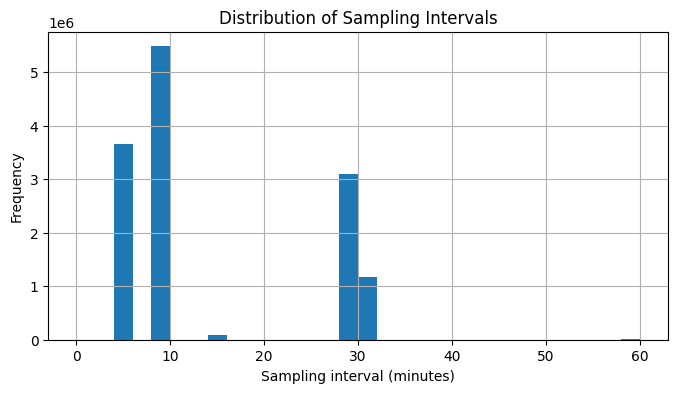

In [11]:
plt.figure(figsize=(8,4))
df['gap_min'].dropna().clip(upper=60).hist(bins=30)
plt.xlabel('Sampling interval (minutes)')
plt.ylabel('Frequency')
plt.title('Distribution of Sampling Intervals')
plt.show()

In [12]:
station_sampling = df.groupby('station_id')['gap_min'].median().sort_values()
station_sampling.describe()

count    115.000000
mean       9.913043
std        0.656482
min        5.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       10.000000
Name: gap_min, dtype: float64

## Key takeaways

- the dataset is large and station-based, with multiple years of observations
- sampling is **not perfectly regular**; dominant intervals are typically 5 and 10 minutes
- some rows violate the bikes + docks = capacity relation, so this must be treated as a data quality issue
- station `507` is suspicious (capacity 1, unnamed) and should be excluded from the cleaned dataset